<a href="https://colab.research.google.com/github/aurora-nat/machine-vision-course/blob/main/labs/lab6/Contrastive_Self_Supervised_Learning__CLIP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CLIP in action: classify and search real photographs

**Try three capabilities:** type a sentence to find photographs; supply your own category names to classify images; use one photograph to find similar photographs. The results appear as **actual photos with model-computed rankings and scores**. Edit the inputs and rerun the application cells.

**CLIP** means *Contrastive Language–Image Pretraining*. [OpenAI](https://openai.com/index/clip/), trained on **400 million Internet image–text pairs**—a major milestone in vision–language models.

**Colab:** choose **Runtime → Change runtime type → T4 GPU**, then **Run all**. This version uses OpenAI's **ViT-B/32** checkpoint, with approximately **605 MB of weights**, and one **95 MB Flickr8k data file**. Downloads are cached. No Hugging Face token is needed. A short, optional training exercise comes after the applications.


In [1]:
%pip -q install "transformers>=4.57,<6" "datasets>=3.6,<6"

import os, io, random, hashlib, textwrap, re
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from datasets import load_dataset, Image as HFImage, disable_progress_bars as disable_dataset_bars
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import disable_progress_bars
from transformers import AutoProcessor, CLIPModel, set_seed
from transformers.utils import logging as transformers_logging

disable_progress_bars(); disable_dataset_bars(); transformers_logging.disable_progress_bar()
set_seed(42); torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "openai/clip-vit-base-patch32"
processor = AutoProcessor.from_pretrained(model_id, token=False)
# This official checkpoint supplies PyTorch .bin weights; current Colab supports their loading.
model = CLIPModel.from_pretrained(model_id, token=False, use_safetensors=False).float().to(device).eval()
stage = "pretrained CLIP"
MAX_TEXT = model.config.text_config.max_position_embeddings
CYAN, PINK, YELLOW = "#BDEFF7", "#F6C5DF", "#FFF1A8"
print("Model:", model_id, "| Device:", device)


Model: openai/clip-vit-base-patch32 | Device: cuda


## 1. Our searchable photo collection

Load **up to 320 distinct Flickr8k photographs**, with one recorded caption per photo, for people, sports, and outdoor examples. We skip images whose available captions mention dogs, cats, or other common pets. This is a caption-based filter. The data file repeats photos with different captions, so we check all available captions for each image, then remove repeated image bytes and caption token sequences. Captions help us inspect results; **text-to-image search will rank image embeddings, without searching caption keywords**.


Gallery: 320 photographs after caption filtering and deduplication.


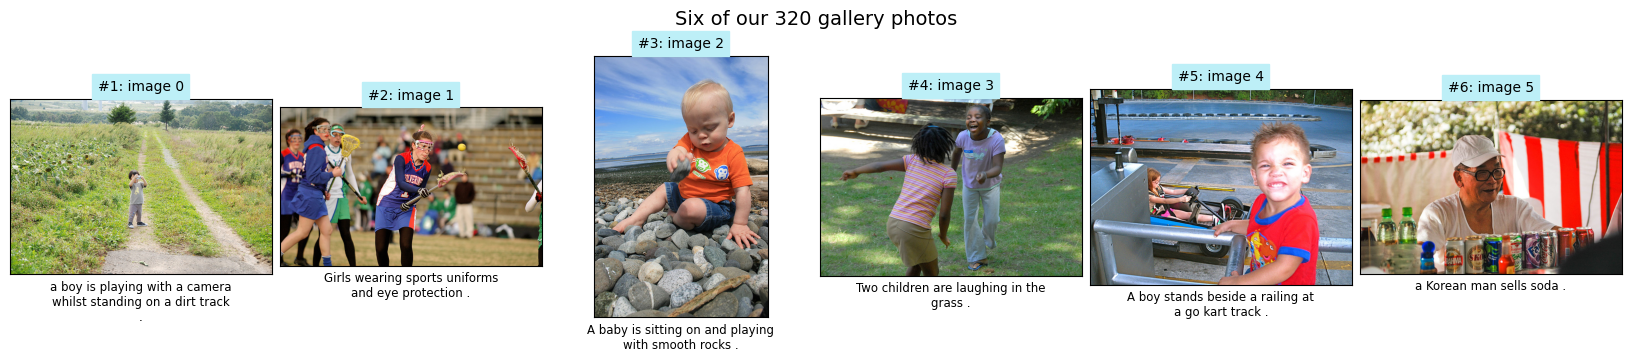

In [2]:
path = hf_hub_download("ariG23498/flickr8k", repo_type="dataset",
    filename="data/train-00000-of-00012.parquet",
    revision="685166696305f65f525fc3f23b5a49f0139c7a73", token=False)
raw = load_dataset("parquet", data_files=path, split="train").cast_column("image", HFImage(decode=False))

PET_WORDS = re.compile(
    r"\b(?:dogs?|pupp(?:y|ies)|cats?|kittens?|pets?|poodles?|retrievers?|terriers?|"
    r"labradors?|beagles?|husk(?:y|ies)|bulldogs?|collies?|spaniels?|hounds?|"
    r"chihuahuas?|dachshunds?|rottweilers?|hamsters?|gerbils?|rabbits?|bunnies|"
    r"ferrets?|parrots?|parakeets?|guinea pigs?)\b", re.IGNORECASE)

def collect_photos(rows, count=320):
    # Exclude an image if ANY of its available captions mentions a pet.
    excluded = {hashlib.sha256(row["image"]["bytes"]).hexdigest() for row in rows
                if PET_WORDS.search(row["caption"] or "")}
    records, seen_images, seen_text = [], set(), set()
    for row in rows:
        payload = row["image"]["bytes"]
        image_id = hashlib.sha256(payload).hexdigest()
        caption = " ".join((row["caption"] or "").split())
        if image_id in excluded or image_id in seen_images or not caption:
            continue
        text_id = tuple(processor.tokenizer(caption, truncation=True, max_length=MAX_TEXT)["input_ids"])
        if text_id in seen_text:
            continue
        with Image.open(io.BytesIO(payload)) as im:
            photo = im.convert("RGB")
        records.append(dict(image=photo, caption=caption, image_id=image_id))
        seen_images.add(image_id); seen_text.add(text_id)
        if len(records) == count:
            break
    assert len(records) >= 16, "Need at least 16 distinct eligible photos for this lesson."
    return records

photos = collect_photos(raw)
random.Random(42).shuffle(photos)

def display_photos(indices, title, scores=None, query=None):
    indices = list(indices)
    shown = ([query] if query is not None else []) + indices
    fig, axes = plt.subplots(1, len(shown), figsize=(2.7 * len(shown), 3.5),
                             squeeze=False, constrained_layout=True)
    for position, (ax, idx) in enumerate(zip(axes.flat, shown)):
        ax.imshow(photos[idx]["image"]); ax.set(xticks=[], yticks=[])
        is_query = query is not None and position == 0
        rank = position - int(query is not None)
        label = f"QUERY: image {idx}" if is_query else f"#{rank+1}: image {idx}"
        if scores is not None and not is_query:
            label += f" | cosine {float(scores[rank]):.3f}"
        ax.set_title(label, fontsize=10, backgroundcolor=PINK if is_query else CYAN)
        ax.set_xlabel(textwrap.fill(photos[idx]["caption"], 32), fontsize=8.5)
    fig.suptitle(title, fontsize=14)
    plt.show()

print(f"Gallery: {len(photos)} photographs after caption filtering and deduplication.")
display_photos(range(6), f"Six of our {len(photos)} gallery photos")


## 2. The shared space makes these applications possible

The image and text encoders have separate weights. Each produces features; a learned linear projection maps them to the common **512-dimensional** space. Normalize each vector to length one. Then a dot product measures **cosine similarity**: a larger value means a closer match.


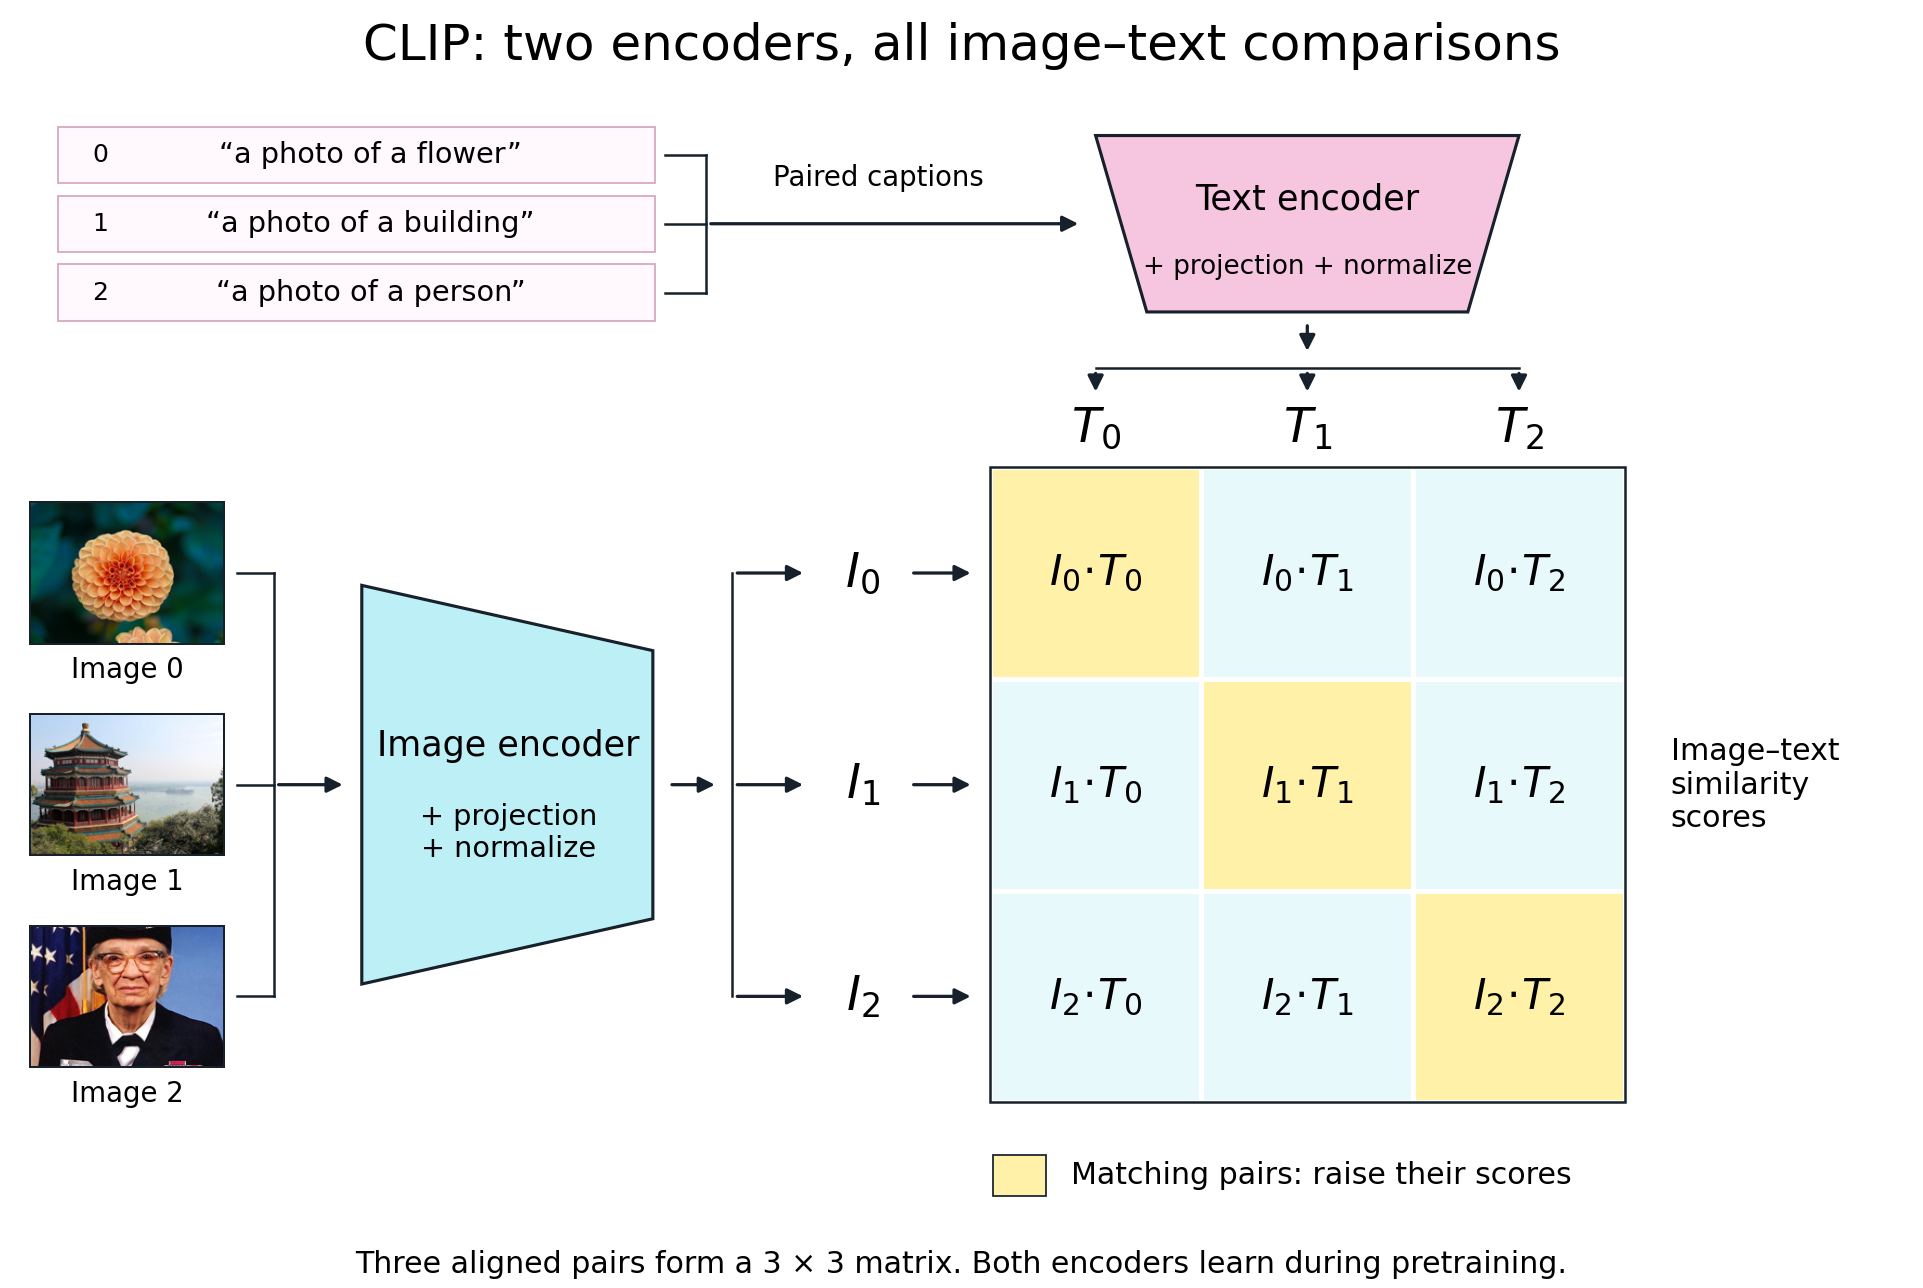

The schematic shows matched training pairs. Below, we use the pretrained encoders explicitly and encode the gallery **once**. `pooler_output` is one vector representing the complete image or text. The cached vectors make subsequent searches fast.


In [3]:
@torch.no_grad()
def image_pool(images):
    batch = processor(images=images, return_tensors="pt").to(device)
    return model.vision_model(pixel_values=batch["pixel_values"], return_dict=True).pooler_output

@torch.no_grad()
def text_pool(texts):
    batch = processor(text=texts, padding=True, truncation=True,
                      max_length=MAX_TEXT, return_tensors="pt").to(device)
    return model.text_model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                            return_dict=True).pooler_output

@torch.no_grad()
def encode_text(texts):
    return F.normalize(model.text_projection(text_pool(texts)), dim=-1)

# Keep frozen, pre-projection features too: the optional exercise can reuse them.
image_pools, caption_pools = [], []
for start in range(0, len(photos), 32):
    group = photos[start:start+32]
    image_pools.append(image_pool([p["image"] for p in group]))
    caption_pools.append(text_pool([p["caption"] for p in group]))
image_pools, caption_pools = torch.cat(image_pools), torch.cat(caption_pools)

@torch.no_grad()
def refresh_index():
    global image_embeddings, caption_embeddings
    image_embeddings = F.normalize(model.visual_projection(image_pools), dim=-1)
    caption_embeddings = F.normalize(model.text_projection(caption_pools), dim=-1)

refresh_index()
assert image_embeddings.shape == (len(photos), 512)
assert torch.allclose(image_embeddings.norm(dim=1), torch.ones(len(photos), device=device), atol=1e-5)
print("Search index:", tuple(image_embeddings.shape), f"= {len(photos)} photos × 512 features")


Search index: (320, 512) = 320 photos × 512 features


## 3. Type a description → retrieve photographs

Type what you want to find. CLIP embeds your sentence and compares it with every image vector, then shows the **five highest-scoring photos**. It can match the meaning of a description even when that wording is absent from the recorded caption.

**Edit `queries` below.** For example, try “people playing a sport,” “a person riding a bicycle,” or “someone climbing.” Search is limited to photos in this collection; inspect the returned pictures rather than assuming every result is correct.


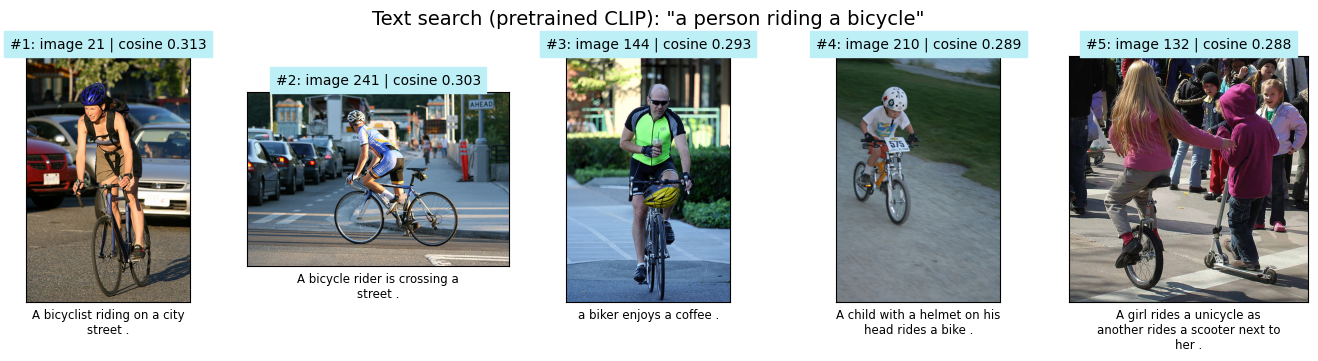

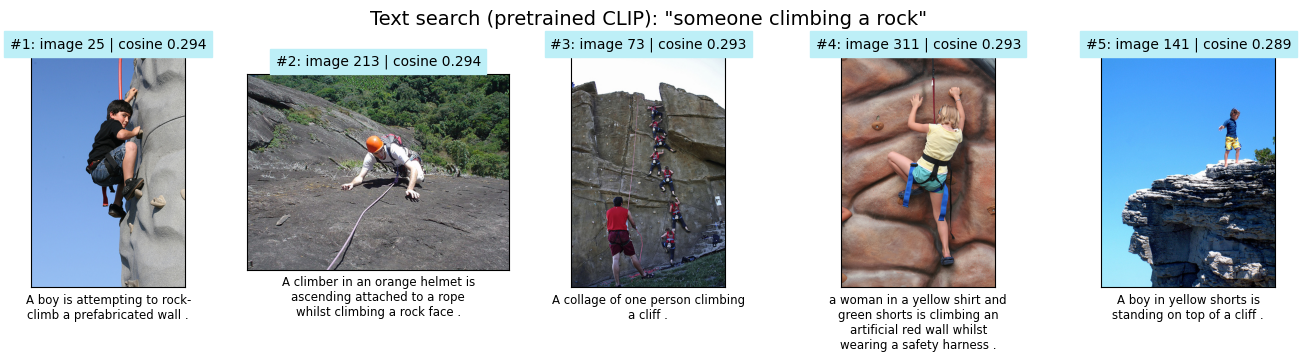

In [4]:
@torch.no_grad()
def search_text(query, k=5):
    query_vector = encode_text([query])
    similarity = image_embeddings @ query_vector[0]  # Compare with image pixels encoded above.
    values, indices = similarity.topk(min(k, len(photos)))
    display_photos(indices.cpu().tolist(), f'Text search ({stage}): "{query}"', values.cpu())
    return indices.cpu().tolist()

queries = ["a person riding a bicycle", "someone climbing a rock"]  # Edit these and rerun.
for query in queries:
    search_text(query)


## 4. Zero-shot classification: supply your own labels

CLIP can compare a photo with descriptions of **your own categories**, without fitting a new classifier. We look for cycling, climbing, and outdoor-play photos using caption keywords **before checking CLIP's predictions**. This is a demonstration, not an accuracy benchmark.

**Zero-shot** here means using pretrained weights without new labeled training for this classification task. The concepts may have appeared during pretraining.

Edit `labels` and rerun. The bars show the **top three of all supplied labels**. Softmax percentages are relative to this candidate set; all candidates' probabilities sum to one. If the appropriate category is missing, CLIP still selects an available candidate.


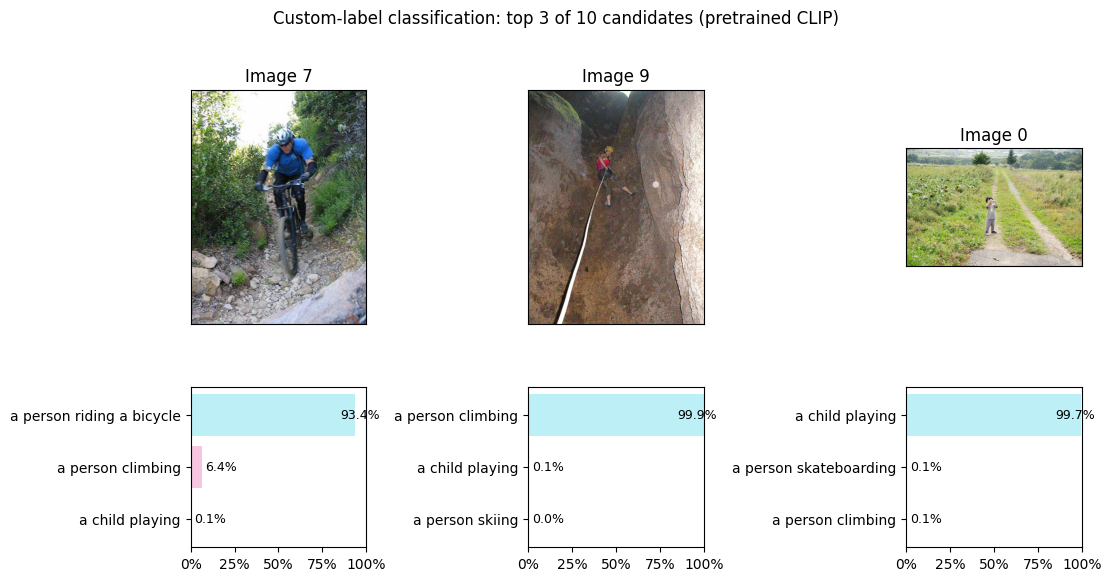

In [5]:
# Select diverse inputs transparently, using metadata rather than model scores.
example_ids = []
topics = {"cycling": ("bicycle", "bike", "cycling", "cyclist"),
          "climbing": ("climb", "climbing", "climber", "climbs"),
          "outdoor play": ("child", "children", "boy", "girl")}
for topic, words in topics.items():
    idx = next((i for i, p in enumerate(photos)
                if i not in example_ids and any(re.search(rf"\b{word}\b", p["caption"], re.I)
                                                for word in words)), None)
    if idx is None:
        idx = next(i for i in range(len(photos)) if i not in example_ids)
        print(f"No '{topic}' caption found; using image {idx} as another example.")
    example_ids.append(idx)

labels = ["a person riding a bicycle", "a person climbing", "a child playing",
          "a person playing basketball", "a person swimming", "a person skateboarding",
          "a person skiing", "a building", "a boat", "a car"]  # Edit these descriptions.
assert len(labels) >= 2
with torch.no_grad():
    label_vectors = encode_text([f"a photo of {label}" for label in labels])
    logits = model.logit_scale.exp() * (image_embeddings[example_ids] @ label_vectors.T)
    probabilities = logits.softmax(dim=1)  # Normalize across ALL labels before taking top 3.

fig, axes = plt.subplots(2, 3, figsize=(11, 5.7), height_ratios=[3, 1.4], constrained_layout=True)
for column, idx in enumerate(example_ids):
    axes[0, column].imshow(photos[idx]["image"])
    axes[0, column].set(xticks=[], yticks=[], title=f"Image {idx}")
    values, order = probabilities[column].topk(min(3, len(labels)))
    ax = axes[1, column]
    ax.barh(range(len(order)), values.cpu().tolist(), color=[CYAN, PINK, YELLOW][:len(order)])
    ax.set(yticks=range(len(order)), yticklabels=[labels[j] for j in order.cpu().tolist()], xlim=(0, 1))
    ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1))
    for j, value in enumerate(values.cpu().tolist()):
        ax.text(min(value + .02, .85), j, f"{value:.1%}", va="center", fontsize=9)
fig.suptitle(f"Custom-label classification: top 3 of {len(labels)} candidates ({stage})")
plt.show()


## 5. Use a photo → find similar photos

Select a gallery image as the query. Compare its image vector with every other image vector. **No text query is needed.** The query is excluded from its own results, and repeated photos were removed when loading the gallery.

Edit `query_image` to search with another photograph. Similarity can reflect objects, activity, or overall scene; inspect what the model emphasizes.


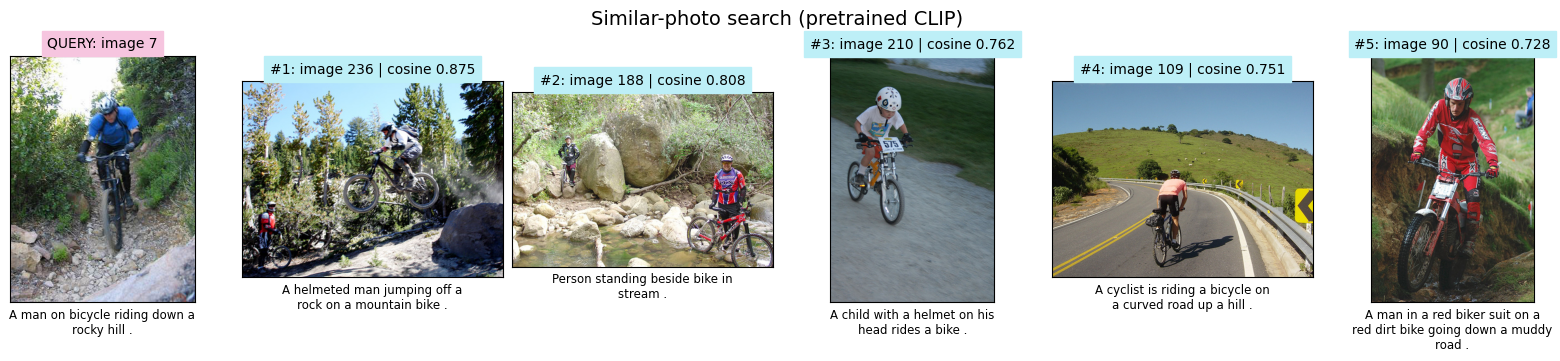

[236, 188, 210, 109, 90]

In [6]:
@torch.no_grad()
def search_image(query_image, k=5):
    assert 0 <= query_image < len(photos)
    similarity = (image_embeddings @ image_embeddings[query_image]).clone()
    similarity[query_image] = -torch.inf  # Never return the query itself.
    values, indices = similarity.topk(min(k, len(photos) - 1))
    display_photos(indices.cpu().tolist(), f"Similar-photo search ({stage})", values.cpu(), query=query_image)
    return indices.cpu().tolist()

query_image = example_ids[0]  # Start with the first example; choose any gallery image index.
search_image(query_image)


## 6. How did CLIP learn this ability?

For normalized image vector $u_i$ and text vector $v_j$, CLIP computes

$$S_{ij}=e^s u_i^\top v_j.$$

$i$ indexes images and $j$ indexes captions in the batch. $s$ is a learned scalar log-scale; $e^s$ is positive. A positive scale preserves similarity rankings; a larger scale makes the softmax more peaked. In a batch of $B$ aligned pairs, row $i$ should select caption $i$ and column $i$ should select image $i$. Targets are **batch positions**, rather than category labels:

$$\mathcal L=\tfrac12[\operatorname{CE}(S,[0,\ldots,B-1])+
\operatorname{CE}(S^\top,[0,\ldots,B-1])].$$

**CE** means cross-entropy, including log-softmax. The diagonal holds the recorded matches; the other candidates compete with them. The following numbers come from four actual photo–caption pairs and are checked against Hugging Face's calculation.


Learned scale: 100.000; measured paired loss: 0.0118


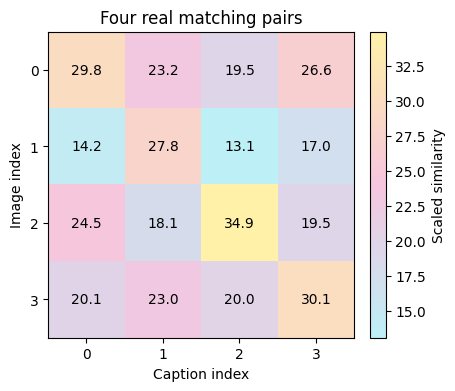

In [7]:
def clip_loss(scores):
    assert scores.ndim == 2 and scores.shape[0] == scores.shape[1] >= 2
    target = torch.arange(len(scores), device=scores.device)
    return (F.cross_entropy(scores, target) + F.cross_entropy(scores.T, target)) / 2

with torch.no_grad():
    pair_scores = model.logit_scale.exp() * (image_embeddings[:4] @ caption_embeddings[:4].T)
    batch = processor(images=[p["image"] for p in photos[:4]], text=[p["caption"] for p in photos[:4]],
                      padding=True, truncation=True, max_length=MAX_TEXT, return_tensors="pt").to(device)
    reference = model(**batch, return_loss=True)
assert torch.allclose(pair_scores, reference.logits_per_image, rtol=1e-4, atol=1e-4)
assert torch.allclose(clip_loss(pair_scores), reference.loss, rtol=1e-4, atol=1e-4)
print(f"Learned scale: {model.logit_scale.exp().item():.3f}; measured paired loss: {clip_loss(pair_scores).item():.4f}")
fig, ax = plt.subplots(figsize=(4.5, 3.8), constrained_layout=True)
palette = LinearSegmentedColormap.from_list("clip", [CYAN, PINK, YELLOW])
im = ax.imshow(pair_scores.cpu().numpy(), cmap=palette)
ax.set(xticks=range(4), yticks=range(4), xlabel="Caption index", ylabel="Image index", title="Four real matching pairs")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{pair_scores[i, j].item():.1f}", ha="center", va="center", color="black")
fig.colorbar(im, ax=ax, label="Scaled similarity"); plt.show()


## Optional: watch the projection matrices learn

The applications above use the pretrained model. This short exercise performs **20 real optimizer updates** on recorded photo–caption pairs. One update uses 16 pairs. We freeze both encoders and the score scale, and train the **two existing projection matrices**. This is **projection-only fine-tuning**, with no LoRA adapters. The image and text Transformers—including their query, key, value, and MLP weights—remain frozen.

We plot loss on a fixed 16-pair training subset while other training batches are sampled. Fitting these pairs does not establish improved search quality. Afterward, we rebuild the projected gallery index so rerunning an application consistently uses the adapted projections.


Update 5: fixed training-subset loss = 0.1098
Update 10: fixed training-subset loss = 0.1056
Update 15: fixed training-subset loss = 0.1015
Update 20: fixed training-subset loss = 0.0988
20 updates; 655,360 trainable parameters; max weight change 0.000187


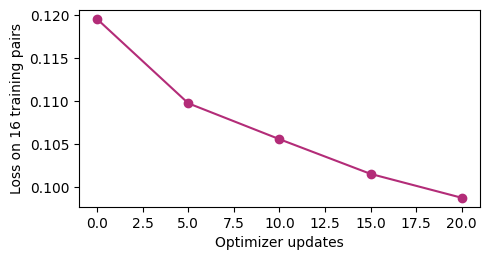

Gallery index refreshed. Rerun a search to inspect how its results changed.


In [8]:
RUN_TRAINING = True  # Set True to run the optional exercise; default searches use pretrained CLIP.
if RUN_TRAINING:
    model.requires_grad_(False)
    trainable = list(model.visual_projection.parameters()) + list(model.text_projection.parameters())
    for parameter in trainable:
        parameter.requires_grad_(True)
    optimizer = torch.optim.AdamW(trainable, lr=1e-5, weight_decay=0.0)
    before = [p.detach().clone() for p in trainable]
    def training_scores(ids):
        u = F.normalize(model.visual_projection(image_pools[ids]), dim=-1)
        v = F.normalize(model.text_projection(caption_pools[ids]), dim=-1)
        return model.logit_scale.exp() * (u @ v.T)
    monitor = torch.arange(16, device=device)
    with torch.no_grad():
        trace = [(0, clip_loss(training_scores(monitor)).item())]
    for step in range(1, 21):
        ids = torch.randperm(len(photos), device=device)[:16]
        optimizer.zero_grad(set_to_none=True)
        loss = clip_loss(training_scores(ids))
        assert torch.isfinite(loss)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable, 1.0, error_if_nonfinite=True)
        optimizer.step()
        if step % 5 == 0:
            with torch.no_grad():
                trace.append((step, clip_loss(training_scores(monitor)).item()))
            print(f"Update {step}: fixed training-subset loss = {trace[-1][1]:.4f}")
    change = max((p.detach() - old).abs().max().item() for p, old in zip(trainable, before))
    assert change > 0 and torch.isfinite(torch.tensor(change))
    print(f"20 updates; {sum(p.numel() for p in trainable):,} trainable parameters; max weight change {change:.3g}")
    plt.figure(figsize=(5, 2.7))
    plt.plot([s for s, value in trace], [value for s, value in trace], "o-", color="#B32C78")
    plt.xlabel("Optimizer updates"); plt.ylabel("Loss on 16 training pairs"); plt.tight_layout(); plt.show()
    model.eval(); model.requires_grad_(False)
    refresh_index()
    stage = "adapted projections"
    print("Gallery index refreshed. Rerun a search to inspect how its results changed.")


In [9]:
# Check that fine-tuning ran and saved the previous projection weights.
assert "before" in globals() and len(before) == 2, "Run the fine-tuning cell first."
assert before[0].shape == model.visual_projection.weight.shape
assert before[1].shape == model.text_projection.weight.shape
assert any(not torch.equal(old, now) for old, now in zip(
    before, [model.visual_projection.weight, model.text_projection.weight]
)), "The projection weights have not changed."

# Load a different data file; keep the notebook's pet filtering.
test_path = hf_hub_download("ariG23498/flickr8k", repo_type="dataset",
    filename="data/train-00001-of-00012.parquet",
    revision="685166696305f65f525fc3f23b5a49f0139c7a73", token=False)
test_raw = load_dataset("parquet", data_files=test_path, split="train").cast_column(
    "image", HFImage(decode=False))

def caption_key(text):
    return tuple(processor.tokenizer(
        text, truncation=True, max_length=MAX_TEXT)["input_ids"])

training_images = {p["image_id"] for p in photos}
training_captions = {caption_key(p["caption"]) for p in photos}
test_photos = [p for p in collect_photos(test_raw, count=192)
               if p["image_id"] not in training_images
               and caption_key(p["caption"]) not in training_captions][:128]
assert len(test_photos) >= 16, "Too few new photo–caption pairs."

# Encode once: compare both sets of projections on identical encoder outputs.
model.eval()
with torch.no_grad():
    test_images, test_texts = [], []
    for start in range(0, len(test_photos), 32):
        group = test_photos[start:start+32]
        test_images.append(image_pool([p["image"] for p in group]))
        test_texts.append(text_pool([p["caption"] for p in group]))
    test_images, test_texts = torch.cat(test_images), torch.cat(test_texts)

@torch.no_grad()
def evaluate_projections(image_weight, text_weight):
    u = F.normalize(F.linear(test_images, image_weight.to(device)), dim=-1)
    v = F.normalize(F.linear(test_texts, text_weight.to(device)), dim=-1)
    scores = model.logit_scale.exp() * (u @ v.T)
    target = torch.arange(len(test_photos), device=device)[:, None]
    recall = {}
    for direction, matrix in [("Image-to-text", scores), ("Text-to-image", scores.T)]:
        for k in (1, 5):
            retrieved = matrix.topk(k, dim=1).indices
            correct = (retrieved == target).any(dim=1)
            recall[f"{direction} R@{k}"] = 100 * correct.float().mean().item()
    return recall, clip_loss(scores).item()

baseline, loss_before = evaluate_projections(*before)
adapted, loss_after = evaluate_projections(
    model.visual_projection.weight, model.text_projection.weight)

print(f"Evaluation: {len(test_photos)} pairs excluded from notebook fine-tuning.")
print("Before = before the latest training run. Recall is %, higher is better.")
print(f"{'Metric':<24}{'Before':>9}{'After':>9}{'Change':>10}")
for metric in baseline:
    print(f"{metric:<24}{baseline[metric]:>9.1f}{adapted[metric]:>9.1f}"
          f"{adapted[metric] - baseline[metric]:>+10.1f}")
print(f"Paired loss (lower is better): {loss_before:.4f} → {loss_after:.4f}")
print("R@k: the recorded matching partner appears among the top k results.")

Evaluation: 128 pairs excluded from notebook fine-tuning.
Before = before the latest training run. Recall is %, higher is better.
Metric                     Before    After    Change
Image-to-text R@1            77.3     78.1      +0.8
Image-to-text R@5            97.7     97.7      +0.0
Text-to-image R@1            76.6     76.6      +0.0
Text-to-image R@5            93.8     96.1      +2.3
Paired loss (lower is better): 0.8054 → 0.7791
R@k: the recorded matching partner appears among the top k results.


**Try it yourself**

- Change a search sentence to describe an action or scene, rather than a single object.
- Replace the classification labels with your own descriptions. Then remove the appropriate label and inspect the forced-choice result.
- Search with another photograph. Do neighbors share its main object, colors, or activity?

CLIP returns rankings among the supplied images or descriptions. Inspect both successes and mismatches.

**References:** [CLIP paper](https://arxiv.org/abs/2103.00020), [OpenAI examples](https://github.com/openai/CLIP), [checkpoint](https://huggingface.co/openai/clip-vit-base-patch32), [Hugging Face CLIP](https://huggingface.co/docs/transformers/en/model_doc/clip), [Flickr8k photo–caption data](https://huggingface.co/datasets/ariG23498/flickr8k), and Hodosh et al., [*Framing Image Description as a Ranking Task*](https://doi.org/10.1613/jair.3994).

Diagram photo credits: scikit-learn's flower ([Flickr/vultilion](https://www.flickr.com/photos/vultilion/6056698931/)) and building ([Flickr/danielbuechele](https://www.flickr.com/photos/danielbuechele/6061409035/)), [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/); portrait: public domain, bundled with Matplotlib.

